In [16]:
import sys
sys.path.append("../..")

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

### LightGBM

In [2]:
%load_ext autoreload
%autoreload 2

from przygotowanie_danych_zuzycia_energii import przygotuj_dane_zuzycia_energii

X,y = przygotuj_dane_zuzycia_energii()
train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

#print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
#print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
#print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
lgbm = LGBMRegressor( objective="regression", n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm.fit(X_train, y_train)



lgbm_q = LGBMRegressor(objective="quantile", alpha=0.97, n_estimators=300, learning_rate=0.05,
                       num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm_q.fit(X_train, y_train)

,num_leaves,15
,learning_rate,0.05
,n_estimators,300
,objective,'quantile'
,min_child_samples,40
,random_state,42
,alpha,0.97
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000


In [20]:
# Prognoza zużycia energii na walidacji
y_pred_val = lgbm.predict(X_val)
q_val = lgbm_q.predict(X_val)


# Baseline - mediana zużycia energii dla danej godziny
prof = y_train.groupby(y_train.index.hour).median()
base_val = prof.reindex(y_val.index.hour).values

print("MAE LightGBM:", round(mean_absolute_error(y_val, y_pred_val), 2))
print("MAE baseline:", round(mean_absolute_error(y_val, base_val), 2))

print("RMSE LightGBM:", round(np.sqrt(mean_squared_error(y_val, y_pred_val)), 2))
print("RMSE baseline:", round(np.sqrt(mean_squared_error(y_val, base_val)), 2))

MAE LightGBM: 1.18
MAE baseline: 1.4
RMSE LightGBM: 3.22
RMSE baseline: 4.83


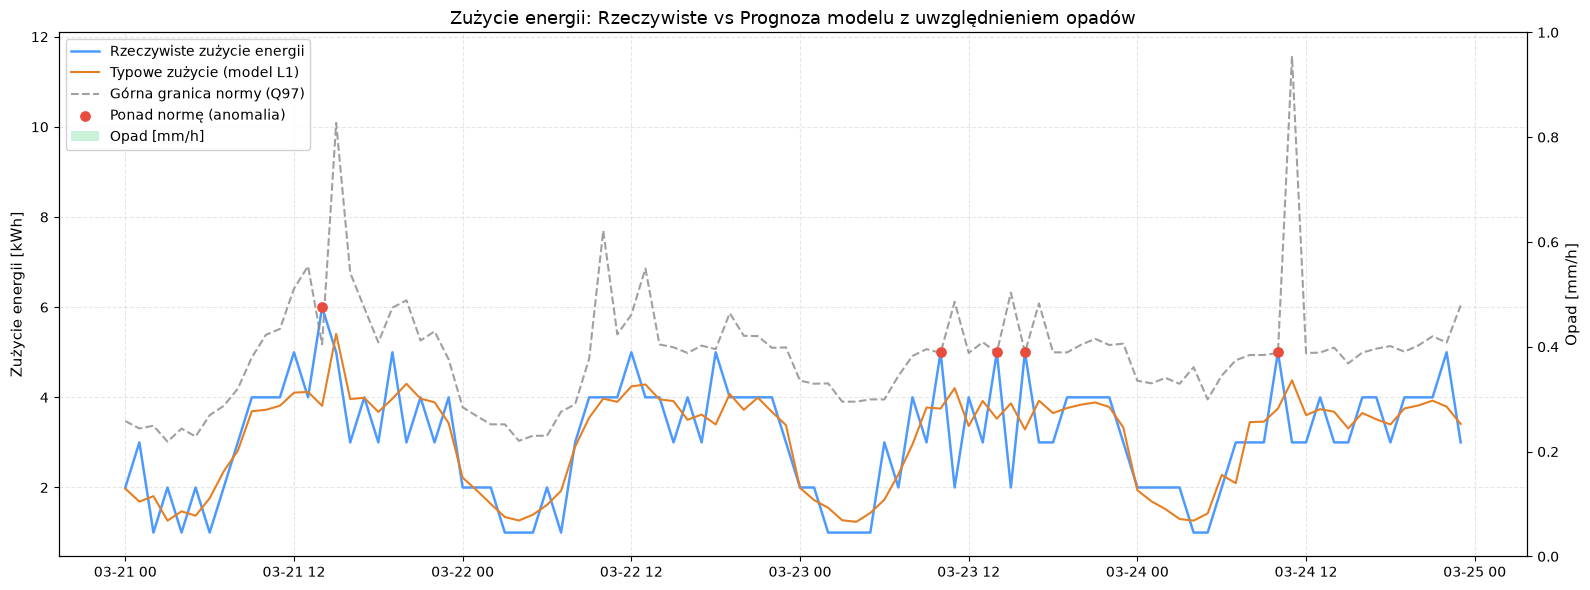

In [21]:
results_val = pd.DataFrame(
    {
        "rzeczywiste": y_val,
        "prognoza": y_pred_val,
        "q97": q_val,
        "opad": X_val["opad_1h"],
    },
    index=y_val.index,
)

sample = results_val.loc["2026-03-21":"2026-03-24"]

# punkty ponad normę
anomalie = sample[sample["rzeczywiste"] > sample["q97"]]

fig, ax1 = plt.subplots(figsize=(16, 6))

# Oś 1: Zużycie energii
ax1.plot(
    sample.index,
    sample["rzeczywiste"],
    label="Rzeczywiste zużycie energii",
    color="#4C9AFF",
    linewidth=1.8,
)
ax1.plot(
    sample.index,
    sample["prognoza"],
    label="Typowe zużycie (model L1)",
    color="#E67E22",
    linewidth=1.5,
)
if "q97" in sample.columns:
  ax1.plot(
      sample.index,
      sample["q97"],
      label="Górna granica normy (Q97)",
      color="#888888",
      linestyle="--",
      alpha=0.8,
  )
  if len(anomalie) > 0:
    ax1.scatter(
        anomalie.index,
        anomalie["rzeczywiste"],
        color="#E74C3C",
        s=45,
        zorder=5,
        label="Ponad normę (anomalia)",
    )

ax1.set_ylabel("Zużycie energii [kWh]", fontsize=11)
ax1.set_title(
    "Zużycie energii: Rzeczywiste vs Prognoza modelu z uwzględnieniem opadów",
    fontsize=13,
)
ax1.grid(True, linestyle="--", alpha=0.3)

# Oś 2: Słupki opadów deszczu w tle
ax2 = ax1.twinx()
ax2.bar(
    sample.index,
    sample["opad"],
    width=0.03,
    color="#2ECC71",
    alpha=0.25,
    label="Opad [mm/h]",
)
ax2.set_ylabel("Opad [mm/h]", fontsize=11)
max_opad = sample["opad"].dropna().max() if not sample["opad"].dropna().empty else 0
ax2.set_ylim(0, max(max_opad * 4, 1.0))

# Połączenie legend z obu osi w jedno okno
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", framealpha=0.9)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# SHAP

C:\Users\Tomek\Desktop\Smart_Water_Challenge_2026\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


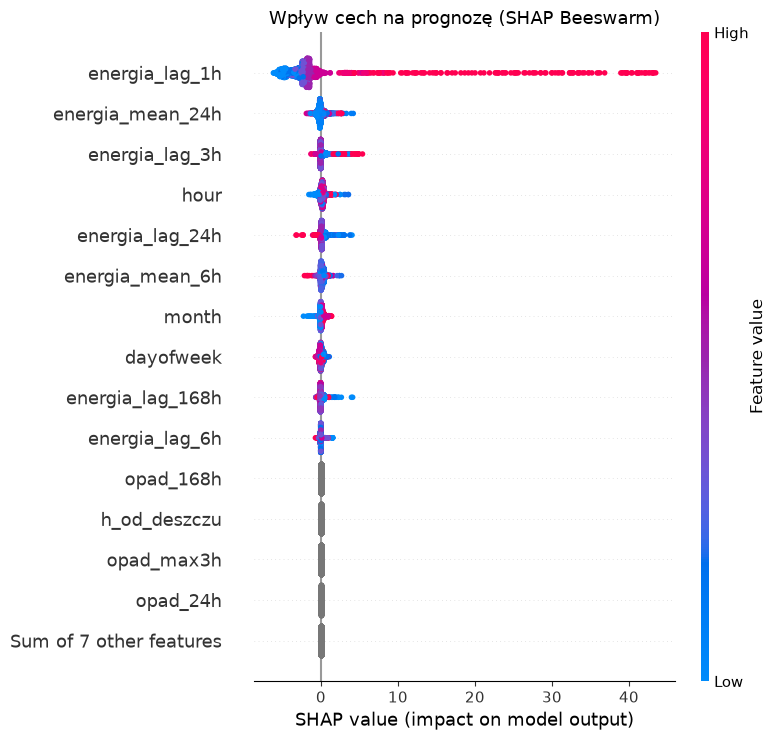

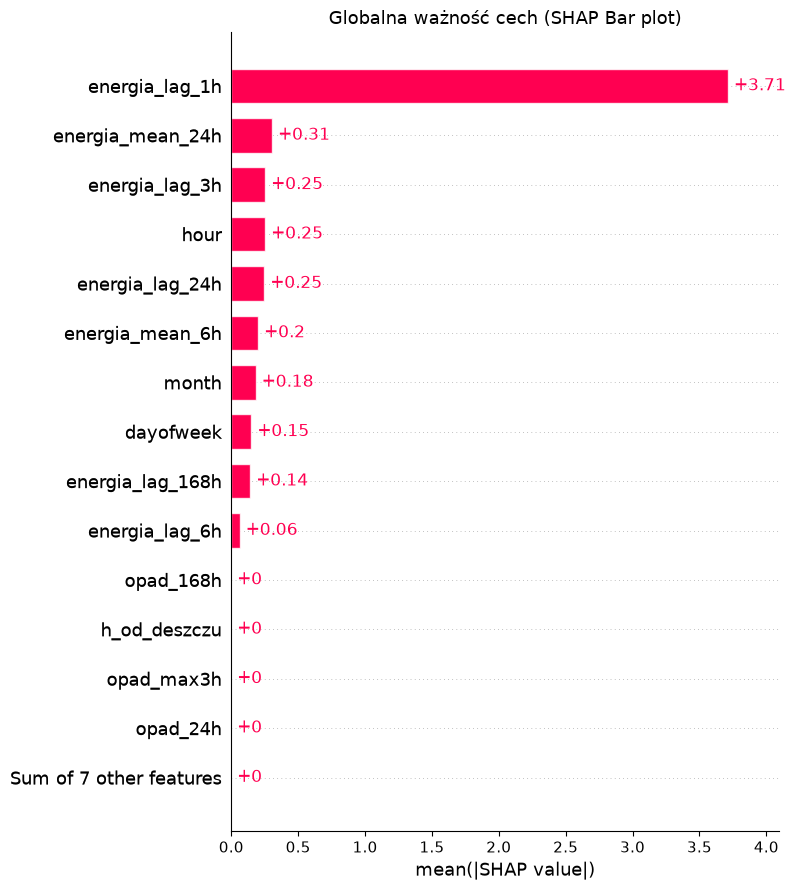

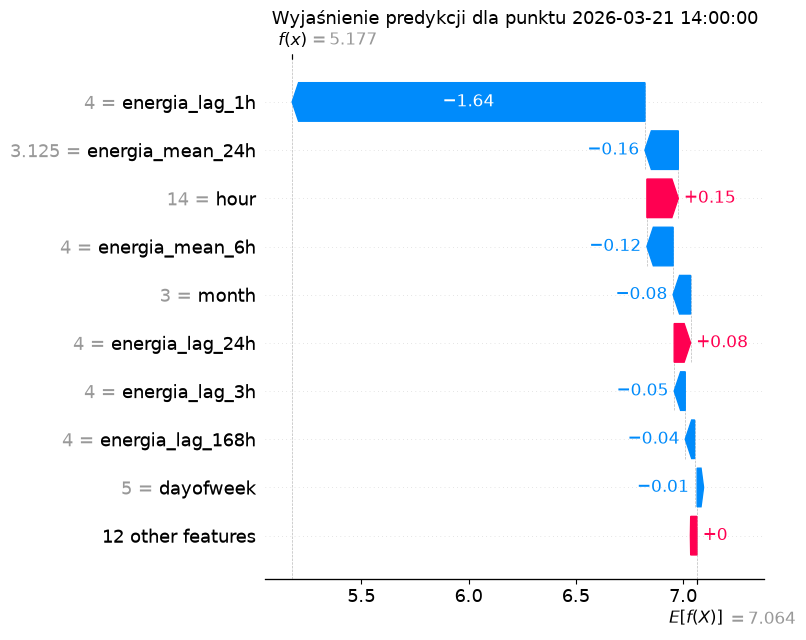

In [22]:
from SHAP import generate_shap_from_tree

generate_shap_from_tree(lgbm_q,X_val,date_with_time="2026-03-21 14:00:00")